# RetailPulse — Day 11: Feature Importance and Optimization

Objectives:
- Load the customer churn feature dataset.
- Train a baseline Random Forest model.
- Analyze feature importance.
- Tune model hyperparameters using cross-validation.
- Compare baseline and tuned performance.
- Save the tuned model and evaluation results.

In [105]:
df = pd.read_excel("../data/transactions.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)
from sklearn.inspection import permutation_importance

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

customers = pd.read_csv(
    OUTPUT_DIR / "day9_customer_churn_features.csv"
)

print("Dataset shape:", customers.shape)
print("Columns:", customers.columns.tolist())
display(customers.head())

Dataset shape: (3550, 8)
Columns: ['CustomerID', 'Frequency', 'Monetary', 'TotalQuantity', 'AverageUnitPrice', 'UniqueProducts', 'Recency', 'ChurnProxy']


,CustomerID,Frequency,Monetary,TotalQuantity,AverageUnitPrice,UniqueProducts,Recency,ChurnProxy
0,12346.0,1,77183.60,74215,1.040000,1,250,1
1,12347.0,5,2790.86,1590,2.797661,82,54,0
2,12348.0,4,1797.24,2341,5.764839,22,0,1
3,12350.0,1,334.40,197,3.841176,17,235,1
4,12352.0,6,1928.06,357,20.670179,40,5,0


In [107]:
feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "AverageUnitPrice",
    "UniqueProducts"
]

X = customers[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

y = customers["ChurnProxy"]

valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype(int).reset_index(drop=True)

print("Feature matrix:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

if y.nunique() != 2:
    raise ValueError(
        "Tuning requires both churn-proxy classes. "
        "Review the Day 9 label definition and data."
    )

if y.value_counts().min() < 5:
    raise ValueError(
        "There are too few examples in one class for "
        "reliable 5-fold stratified cross-validation."
    )

Feature matrix: (3550, 6)

Target distribution:
ChurnProxy
0    1893
1    1657
Name: count, dtype: int64


In [108]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 2840
Testing rows: 710


In [109]:
baseline_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)
baseline_prob = baseline_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.73      0.64      0.68       379
           1       0.64      0.73      0.68       331

    accuracy                           0.68       710
   macro avg       0.68      0.68      0.68       710
weighted avg       0.69      0.68      0.68       710



,Feature,Importance
1,Frequency,0.199258
2,Monetary,0.185310
0,Recency,0.180427
5,UniqueProducts,0.160787
3,TotalQuantity,0.160698
4,AverageUnitPrice,0.113521


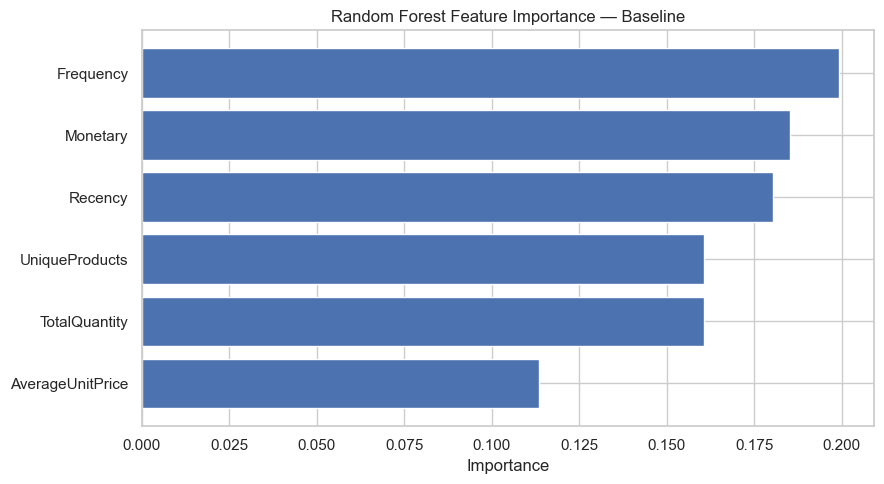

In [110]:
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": baseline_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.title("Random Forest Feature Importance — Baseline")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [111]:
perm = permutation_importance(
    baseline_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": feature_columns,
    "ImportanceMean": perm.importances_mean,
    "ImportanceStd": perm.importances_std
}).sort_values("ImportanceMean", ascending=False)

display(permutation_df)

,Feature,ImportanceMean,ImportanceStd
0,Recency,0.043385,0.013007
1,Frequency,0.037510,0.010359
5,UniqueProducts,0.034517,0.007631
4,AverageUnitPrice,0.014694,0.007592
2,Monetary,0.000724,0.003320
3,TotalQuantity,-0.004453,0.014835


In [112]:
param_distributions = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [None, 5, 8, 12, 16],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.8],
    "class_weight": ["balanced", "balanced_subsample"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train)

tuned_model = search.best_estimator_

print("Best parameters:")
print(search.best_params_)

print("\nBest cross-validation average precision:")
print(round(search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 0.8, 'max_depth': 5, 'class_weight': 'balanced_subsample'}

Best cross-validation average precision:
0.6863


In [113]:
def evaluate_classifier(model, X_eval, y_eval, model_name):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]

    return {
        "Model": model_name,
        "Precision": precision_score(
            y_eval, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, pred, zero_division=0
        ),
        "F1": f1_score(
            y_eval, pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_eval, prob),
        "AveragePrecision": average_precision_score(
            y_eval, prob
        )
    }

comparison = pd.DataFrame([
    evaluate_classifier(
        baseline_model, X_test, y_test, "Baseline Random Forest"
    ),
    evaluate_classifier(
        tuned_model, X_test, y_test, "Tuned Random Forest"
    )
])

display(comparison.round(4))

,Model,Precision,Recall,F1,ROC_AUC,AveragePrecision
0,Baseline Random Forest,0.6383,0.7251,0.6789,0.7479,0.6891
1,Tuned Random Forest,0.6240,0.7372,0.6759,0.7485,0.6951


In [114]:
importance_df.to_csv(
    OUTPUT_DIR / "day11_feature_importance.csv",
    index=False
)

permutation_df.to_csv(
    OUTPUT_DIR / "day11_permutation_importance.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "day11_model_comparison.csv",
    index=False
)

pd.DataFrame(search.cv_results_).to_csv(
    OUTPUT_DIR / "day11_hyperparameter_search.csv",
    index=False
)

joblib.dump(
    tuned_model,
    OUTPUT_DIR / "day11_tuned_churn_model.pkl"
)

print("Day 11 outputs saved successfully.")

Day 11 outputs saved successfully.


# RetailPulse — Day 12: Data Drift Detection

Objectives:
- Establish a reference dataset.
- Create a simulated incoming dataset.
- Compare feature distributions.
- Detect potential data drift.
- Save a drift report and visualization.

In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import ks_2samp

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [116]:
reference = pd.read_csv(
    OUTPUT_DIR / "day9_customer_churn_features.csv"
)

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "AverageUnitPrice",
    "UniqueProducts"
]

reference = reference[feature_columns].replace(
    [np.inf, -np.inf], np.nan
).dropna()

print("Reference dataset shape:", reference.shape)
display(reference.describe().T)

Reference dataset shape: (3550, 6)


,count,mean,std,min,25%,50%,75%,max
Recency,3550.0,94.066479,84.991986,0.00,20.000000,67.000000,151.000000,298.00
Frequency,3550.0,3.598873,5.998281,1.00,1.000000,2.000000,4.000000,135.00
Monetary,3550.0,1689.012942,6964.547181,2.90,274.947500,587.930000,1413.372500,203106.64
TotalQuantity,3550.0,986.024507,4073.534058,1.00,137.000000,325.000000,807.000000,143895.00
AverageUnitPrice,3550.0,4.754348,37.205478,0.11,2.268555,3.006737,4.004582,2033.10
UniqueProducts,3550.0,51.541690,70.999298,1.00,14.000000,30.000000,64.000000,1415.00


In [117]:
rng = np.random.default_rng(42)

sample_size = min(500, len(reference))

if sample_size < 20:
    raise ValueError(
        "Too few reference rows for this drift exercise."
    )

incoming = reference.sample(
    n=sample_size,
    replace=len(reference) < sample_size,
    random_state=42
).reset_index(drop=True)

# Simulate a change in customer recency
incoming["Recency"] = incoming["Recency"] + 20

print("Incoming simulated batch:", incoming.shape)
display(incoming.head())

Incoming simulated batch: (500, 6)


,Recency,Frequency,Monetary,TotalQuantity,AverageUnitPrice,UniqueProducts
0,46,1,125.92,49,20.895000,2
1,79,5,991.18,852,3.415294,60
2,71,4,819.33,647,1.734167,10
3,143,1,182.99,76,2.917895,19
4,95,1,393.31,334,3.185366,41


In [118]:
ALPHA = 0.05
n_features = len(feature_columns)
corrected_alpha = ALPHA / n_features

rows = []

for feature in feature_columns:
    ref_values = reference[feature].dropna()
    new_values = incoming[feature].dropna()

    statistic, p_value = ks_2samp(
        ref_values,
        new_values
    )

    drift_detected = p_value < corrected_alpha

    rows.append({
        "Feature": feature,
        "ReferenceMean": ref_values.mean(),
        "IncomingMean": new_values.mean(),
        "ReferenceMedian": ref_values.median(),
        "IncomingMedian": new_values.median(),
        "KSStatistic": statistic,
        "PValue": p_value,
        "AdjustedAlpha": corrected_alpha,
        "DriftDetected": drift_detected
    })

drift_report = pd.DataFrame(rows)

display(
    drift_report.sort_values(
        "PValue",
        ascending=True
    ).round(4)
)

,Feature,ReferenceMean,IncomingMean,ReferenceMedian,IncomingMedian,KSStatistic,PValue,AdjustedAlpha,DriftDetected
0,Recency,94.0665,116.4400,67.0000,88.5000,0.2525,0.0000,0.0083,True
1,Frequency,3.5989,3.3200,2.0000,2.0000,0.0420,0.4107,0.0083,False
3,TotalQuantity,986.0245,918.7820,325.0000,316.5000,0.0365,0.5911,0.0083,False
5,UniqueProducts,51.5417,46.3080,30.0000,29.0000,0.0327,0.7227,0.0083,False
2,Monetary,1689.0129,1619.2688,587.9300,562.7850,0.0326,0.7276,0.0083,False
4,AverageUnitPrice,4.7543,7.8952,3.0067,3.0094,0.0226,0.9750,0.0083,False


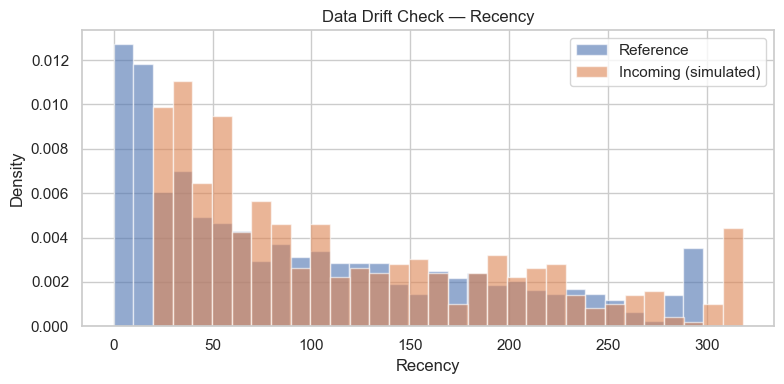

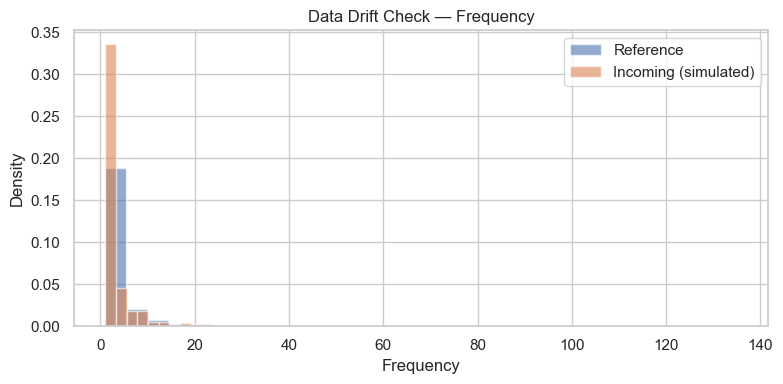

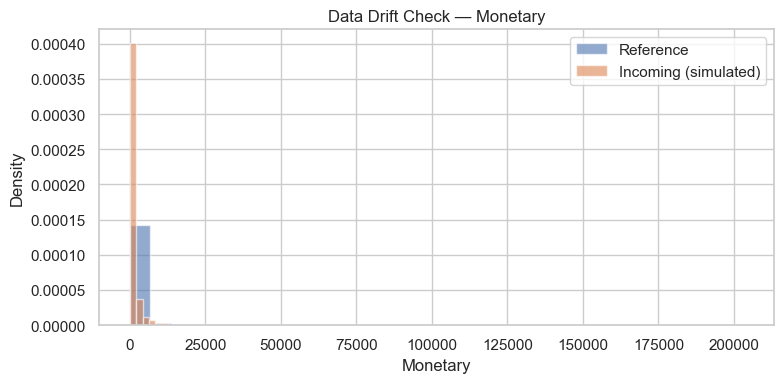

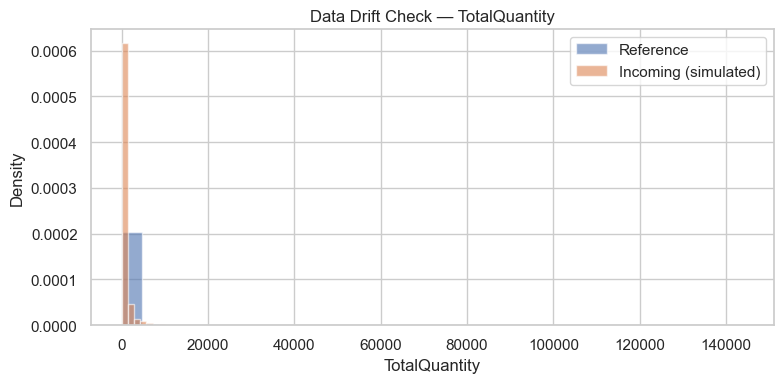

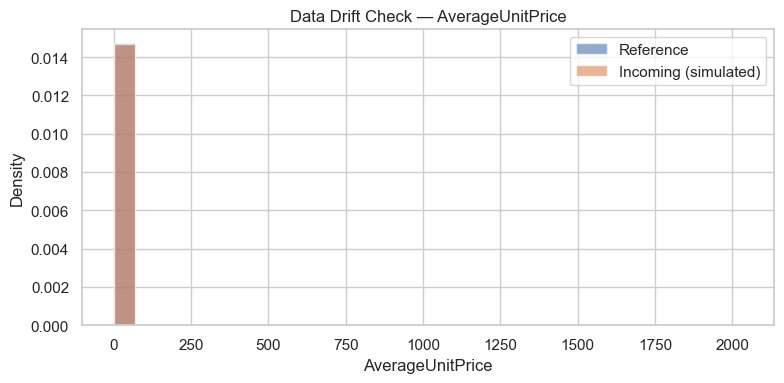

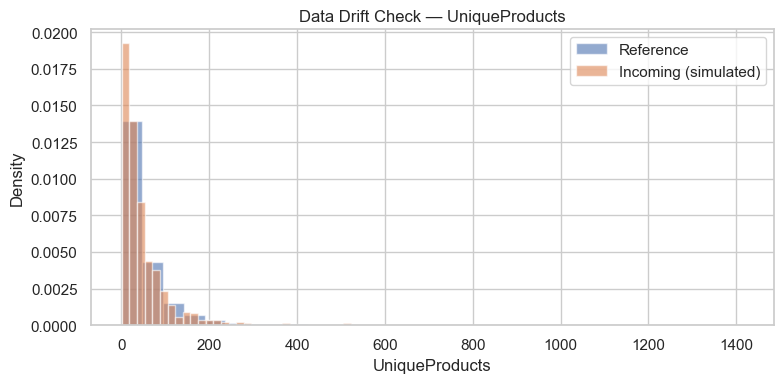

In [119]:
for feature in feature_columns:
    plt.figure(figsize=(8, 4))

    plt.hist(
        reference[feature],
        bins=30,
        alpha=0.6,
        label="Reference",
        density=True
    )

    plt.hist(
        incoming[feature],
        bins=30,
        alpha=0.6,
        label="Incoming (simulated)",
        density=True
    )

    plt.title(f"Data Drift Check — {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [120]:
drift_count = int(drift_report["DriftDetected"].sum())

if drift_count == 0:
    overall_status = "No statistically significant drift detected"
else:
    overall_status = f"Potential drift detected in {drift_count} feature(s)"

print("Monitoring status:", overall_status)

display(
    drift_report[[
        "Feature",
        "KSStatistic",
        "PValue",
        "DriftDetected"
    ]]
)

Monitoring status: Potential drift detected in 1 feature(s)


,Feature,KSStatistic,PValue,DriftDetected
0,Recency,0.252479,4.480098e-25,True
1,Frequency,0.041972,4.107081e-01,False
2,Monetary,0.032563,7.276229e-01,False
3,TotalQuantity,0.036451,5.910830e-01,False
4,AverageUnitPrice,0.022563,9.749841e-01,False
5,UniqueProducts,0.032704,7.227484e-01,False


In [121]:
drift_report.to_csv(
    OUTPUT_DIR / "day12_drift_report.csv",
    index=False
)

incoming.to_csv(
    OUTPUT_DIR / "day12_simulated_incoming_data.csv",
    index=False
)

print("Saved: day12_drift_report.csv")
print("Saved: day12_simulated_incoming_data.csv")

Saved: day12_drift_report.csv
Saved: day12_simulated_incoming_data.csv


-- DAY _ 13 airflow

In [122]:
import pandas as pd

df = pd.read_csv("../outputs/day13_daily_sales_summary.csv")
display(df.head())
print("Rows:", len(df))

,Date,TotalRevenue,TotalUnits,TotalInvoices
0,2010-12-01,58776.79,26818,127
1,2010-12-02,47629.42,31264,142
2,2010-12-03,46898.63,16158,68
3,2010-12-05,31364.63,16242,88
4,2010-12-06,54624.15,21619,102


Rows: 305


#validation of week 2 

In [123]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(r"E:\RetailPulse")
OUTPUT_DIR = PROJECT_DIR / "outputs"
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"

print("Project folder exists:", PROJECT_DIR.exists())
print("Data folder exists:", DATA_DIR.exists())
print("Outputs folder exists:", OUTPUT_DIR.exists())

print("\nNumber of output files:",
      len(list(OUTPUT_DIR.glob("*"))) if OUTPUT_DIR.exists() else 0)

print("\nAvailable output files:")
if OUTPUT_DIR.exists():
    for file in sorted(OUTPUT_DIR.iterdir()):
        print(file.name)

Project folder exists: True
Data folder exists: True
Outputs folder exists: True

Number of output files: 36

Available output files:
day10_daily_product_demand.csv
day10_inventory_recommendations.csv
day11_feature_importance.csv
day11_hyperparameter_search.csv
day11_model_comparison.csv
day11_permutation_importance.csv
day11_tuned_churn_model.pkl
day12_drift_report.csv
day12_simulated_incoming_data.csv
day13_daily_sales_summary.csv
day1_correlation_matrix.csv
day1_missing_values.csv
day2_cleaned_transactions.csv
day2_daily_sales_features.csv
day2_rfm_features.csv
day2_sales_data.csv
day3_cluster_summary.csv
day3_customer_segments.csv
day3_kmeans_evaluation.csv
day4_daily_time_series.csv
day4_monthly_revenue.csv
day4_test.csv
day4_train.csv
day5_prophet_metrics.csv
day5_prophet_model.json
day5_prophet_test_forecast.csv
day6_lstm_forecast.csv
day6_lstm_model.pth
day6_lstm_scaler.pkl
day6_model_comparison.csv
day8_ensemble_forecast.csv
day8_model_comparison.csv
day9_churn_feature_importa

In [124]:
expected_files = [
    # Day 1
    "day1_missing_values.csv",
    "day1_correlation_matrix.csv",

    # Day 2
    "day2_cleaned_transactions.csv",
    "day2_sales_data.csv",
    "day2_rfm_features.csv",
    "day2_daily_sales_features.csv",

    # Day 3
    "day3_customer_segments.csv",
    "day3_cluster_summary.csv",
    "day3_kmeans_evaluation.csv",

    # Day 4
    "day4_daily_time_series.csv",
    "day4_train.csv",
    "day4_test.csv",
    "day4_monthly_revenue.csv",

    # Day 5
    "day5_prophet_test_forecast.csv",
    "day5_prophet_metrics.csv",
    "day5_prophet_model.json",

    # Day 6
    "day6_lstm_forecast.csv",
    "day6_model_comparison.csv",
    "day6_lstm_model.pth",
    "day6_lstm_scaler.pkl",

    # Day 8
    "day8_ensemble_forecast.csv",
    "day8_model_comparison.csv",

    # Day 9
    "day9_customer_churn_features.csv",
    "day9_churn_predictions.csv",
    "day9_churn_feature_importance.csv",
    "day9_churn_model.pkl",

    # Day 10
    "day10_inventory_recommendations.csv",
    "day10_daily_product_demand.csv",

    # Day 11
    "day11_feature_importance.csv",
    "day11_permutation_importance.csv",
    "day11_model_comparison.csv",
    "day11_hyperparameter_search.csv",
    "day11_tuned_churn_model.pkl",

    # Day 12
    "day12_drift_report.csv",
    "day12_simulated_incoming_data.csv",

    # Day 13
    "day13_daily_sales_summary.csv",
]

results = []

for filename in expected_files:
    file_path = OUTPUT_DIR / filename

    results.append({
        "File": filename,
        "Exists": file_path.is_file(),
        "Size_KB": round(file_path.stat().st_size / 1024, 2)
        if file_path.is_file() else None
    })

validation_df = pd.DataFrame(results)

display(validation_df)

print("\nExpected files:", len(expected_files))
print("Files found:", int(validation_df["Exists"].sum()))
print("Files missing:", int((~validation_df["Exists"]).sum()))

,File,Exists,Size_KB
0,day1_missing_values.csv,True,0.18
1,day1_correlation_matrix.csv,True,0.19
2,day2_cleaned_transactions.csv,True,50738.16
3,day2_sales_data.csv,True,49671.62
4,day2_rfm_features.csv,True,96.77
5,day2_daily_sales_features.csv,True,20.59
6,day3_customer_segments.csv,True,110.35
7,day3_cluster_summary.csv,True,0.12
8,day3_kmeans_evaluation.csv,True,0.15
9,day4_daily_time_series.csv,True,26.42



Expected files: 36
Files found: 36
Files missing: 0


In [125]:
file_path = OUTPUT_DIR / "day13_daily_sales_summary.csv"

if not file_path.exists():
    print("Day 13 output CSV is missing from the Windows project folder.")
else:
    daily_summary = pd.read_csv(file_path, parse_dates=["Date"])

    required_columns = [
        "Date",
        "TotalRevenue",
        "TotalUnits",
        "TotalInvoices"
    ]

    print("Rows:", len(daily_summary))
    print("Columns:", daily_summary.columns.tolist())
    print("Missing values:", daily_summary.isna().sum().to_dict())
    print("Duplicate dates:", daily_summary["Date"].duplicated().sum())

    assert len(daily_summary) > 0, "The output is empty."
    assert all(col in daily_summary.columns for col in required_columns), \
        "One or more required columns are missing."
    assert daily_summary["Date"].is_monotonic_increasing, \
        "Dates are not sorted."
    assert not daily_summary["Date"].duplicated().any(), \
        "Duplicate dates found."

    print("\nDay 13 validation passed!")
    display(daily_summary.head())

Rows: 305
Columns: ['Date', 'TotalRevenue', 'TotalUnits', 'TotalInvoices']
Missing values: {'Date': 0, 'TotalRevenue': 0, 'TotalUnits': 0, 'TotalInvoices': 0}
Duplicate dates: 0

Day 13 validation passed!


,Date,TotalRevenue,TotalUnits,TotalInvoices
0,2010-12-01,58776.79,26818,127
1,2010-12-02,47629.42,31264,142
2,2010-12-03,46898.63,16158,68
3,2010-12-05,31364.63,16242,88
4,2010-12-06,54624.15,21619,102


In [126]:
metric_files = [
    "day5_prophet_metrics.csv",
    "day6_model_comparison.csv",
    "day8_model_comparison.csv",
    "day11_model_comparison.csv",
]

for filename in metric_files:
    file_path = OUTPUT_DIR / filename

    print(f"\n--- {filename} ---")

    if file_path.exists():
        metrics_df = pd.read_csv(file_path)
        print("Shape:", metrics_df.shape)
        display(metrics_df.head())
    else:
        print("File missing; check Step 3.")


--- day5_prophet_metrics.csv ---
Shape: (1, 4)


,Model,MAE,RMSE,WAPE_Percent
0,Prophet Baseline,18885.854718,29296.783463,40.552693



--- day6_model_comparison.csv ---
Shape: (2, 4)


,Model,MAE,RMSE,WAPE_Percent
0,Prophet Baseline,18885.854718,29296.783463,40.552693
1,LSTM,29734.503906,37482.444317,63.847481



--- day8_model_comparison.csv ---
Shape: (3, 4)


,Model,MAE,RMSE,WAPE_Percent
0,Prophet,18885.854718,29296.783463,40.552693
1,LSTM,29734.501227,37482.444015,63.847474
2,Prophet + LSTM Ensemble,23989.331029,32931.304556,51.511144



--- day11_model_comparison.csv ---
Shape: (2, 6)


,Model,Precision,Recall,F1,ROC_AUC,AveragePrecision
0,Baseline Random Forest,0.638298,0.725076,0.678925,0.747882,0.689071
1,Tuned Random Forest,0.624041,0.737160,0.675900,0.748511,0.695065


In [127]:
report_path = OUTPUT_DIR / "day14_validation_report.csv"

validation_df.to_csv(report_path, index=False)

print("Validation report saved to:")
print(report_path)

Validation report saved to:
E:\RetailPulse\outputs\day14_validation_report.csv
